# 02 · Exploratory plots and road-network connectivity (train + student_test)

In [1]:
import sys, os
from pathlib import Path
_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pathsnap").is_dir()), None)
if _root is None:
    raise RuntimeError("src/pathsnap not found: unzip all zips of the set into the same pathsnap/ folder")
sys.path.insert(0, str(_root / "src")); os.chdir(_root / "notebooks")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from pathsnap import io
from pathsnap.geo import speeds

FIG = "../outputs/figures"
os.makedirs(FIG, exist_ok=True)
inv = pd.read_csv("../outputs/inventory.csv", dtype={"trip": str})

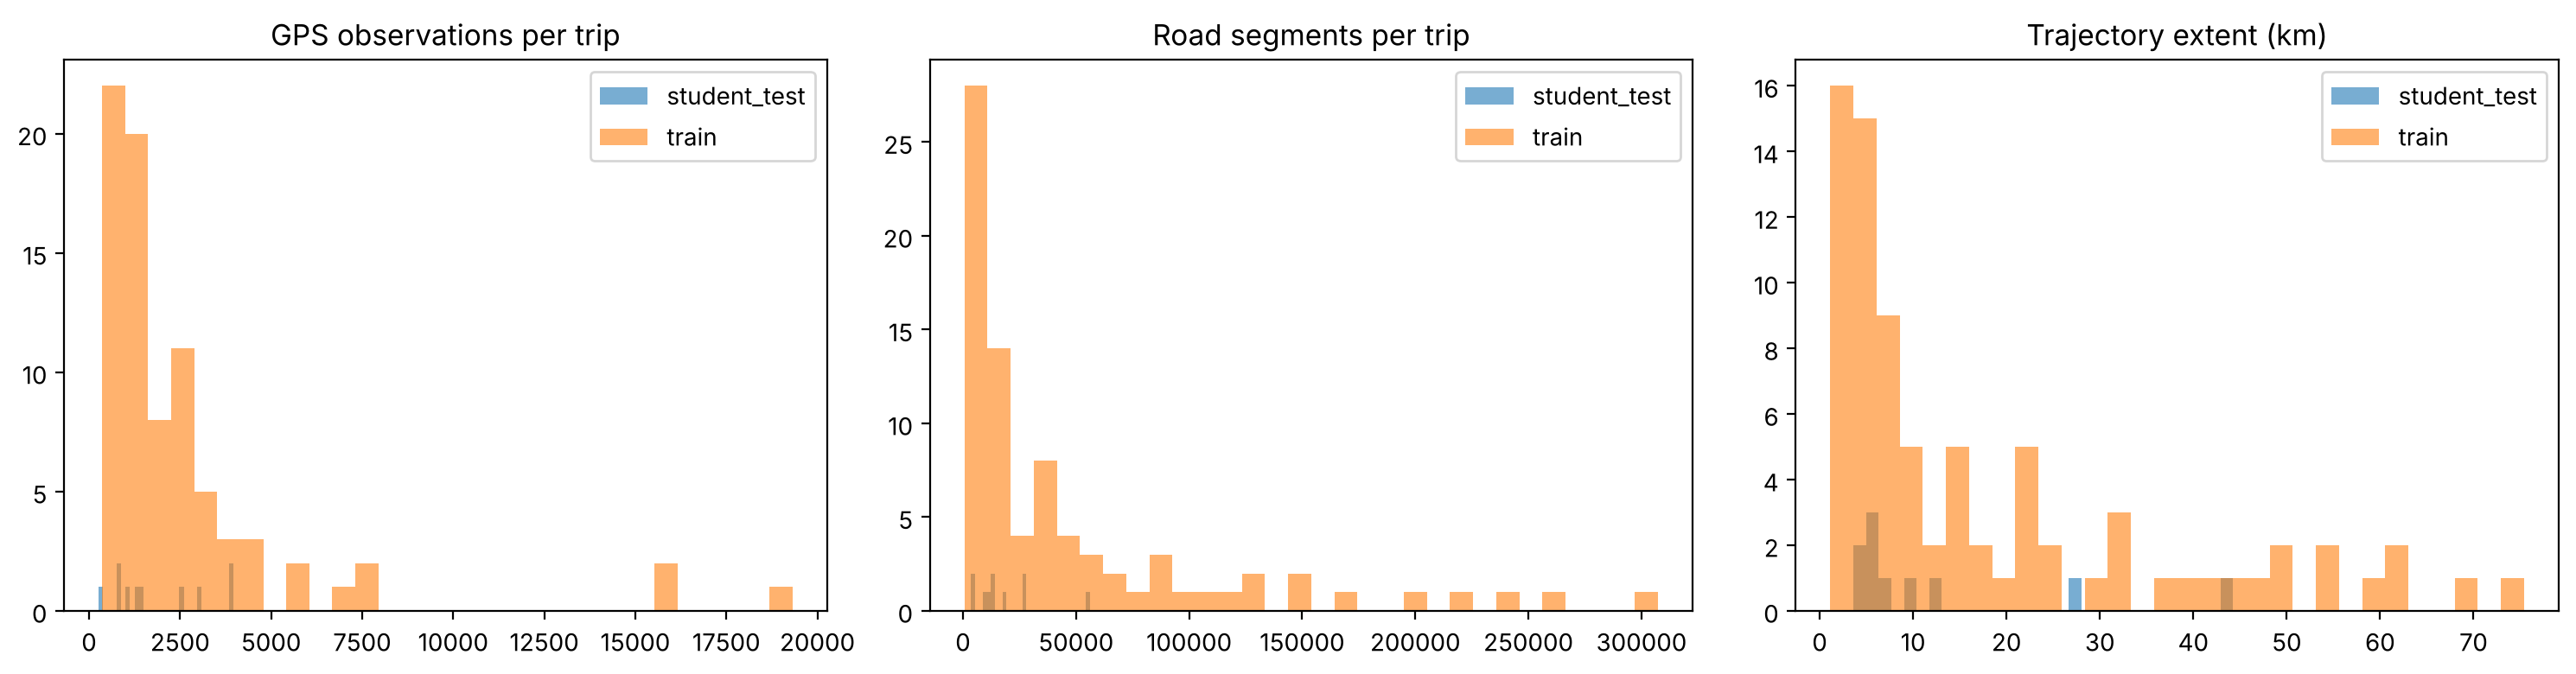

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for s, g in inv.groupby("split"):
    ax[0].hist(g.n_obs, bins=30, alpha=.6, label=s)
    ax[1].hist(g.n_arcs, bins=30, alpha=.6, label=s)
    ax[2].hist(g.extent_km, bins=30, alpha=.6, label=s)
for a, t in zip(ax, ["GPS observations per trip", "Road segments per trip", "Trajectory extent (km)"]):
    a.set_title(t); a.legend()
plt.tight_layout(); plt.savefig(f"{FIG}/eda_trip_sizes.png", dpi=120)

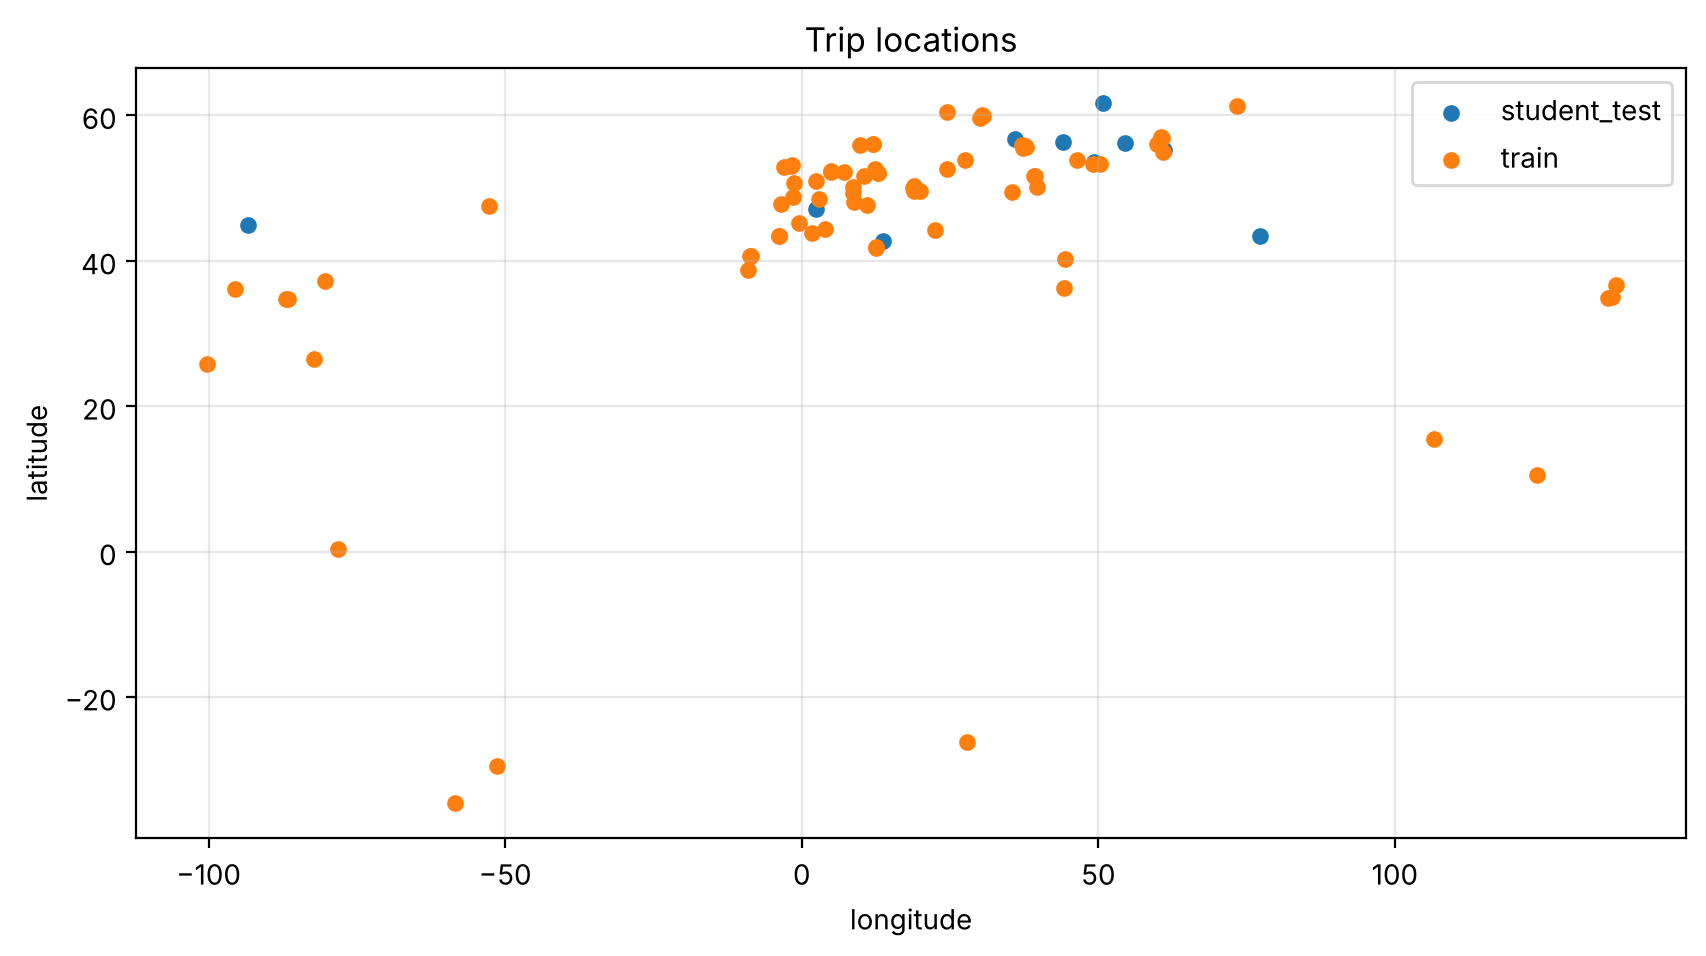

In [3]:
plt.figure(figsize=(10, 5))
for s, g in inv.groupby("split"):
    plt.scatter(g.lon_c, g.lat_c, s=25, label=s)
plt.xlabel("longitude"); plt.ylabel("latitude"); plt.title("Trip locations"); plt.legend(); plt.grid(alpha=.3)
plt.savefig(f"{FIG}/eda_trip_locations.png", dpi=120)

In [4]:
dts, spd, net = [], [], []
for split in ["train", "student_test"]:
    for tid in io.list_trips(split):
        tr = io.load_trip(split, tid)
        v, dt = speeds(tr["pxy"], tr["t"])
        dts.append(dt[1:]); spd.append(v[1:][dt[1:] == 1])
        n, a = len(tr["nodes"]), tr["arcs"]
        g = coo_matrix((np.ones(len(a)), (a[:, 0], a[:, 1])), shape=(n, n))
        nw, lw = connected_components(g, directed=True, connection="weak")
        ns, ls = connected_components(g, directed=True, connection="strong")
        deg = np.bincount(a.ravel(), minlength=n)
        net.append(dict(split=split, trip=tid, nodes=n, arcs=len(a), weak_cc=nw, strong_cc=ns,
                        largest_scc_frac=np.bincount(ls).max() / n, isolated=int((deg == 0).sum()),
                        dead_ends=int((np.bincount(a[:, 0], minlength=n) == 0).sum()),
                        mean_arc_m=tr["alen"].mean()))
net = pd.DataFrame(net)
net.to_csv("../outputs/network_stats.csv", index=False)
dts, spd = np.concatenate(dts), np.concatenate(spd)

dt==1s: 0.967, dt>10s: 617, speed>200km/h steps: 915


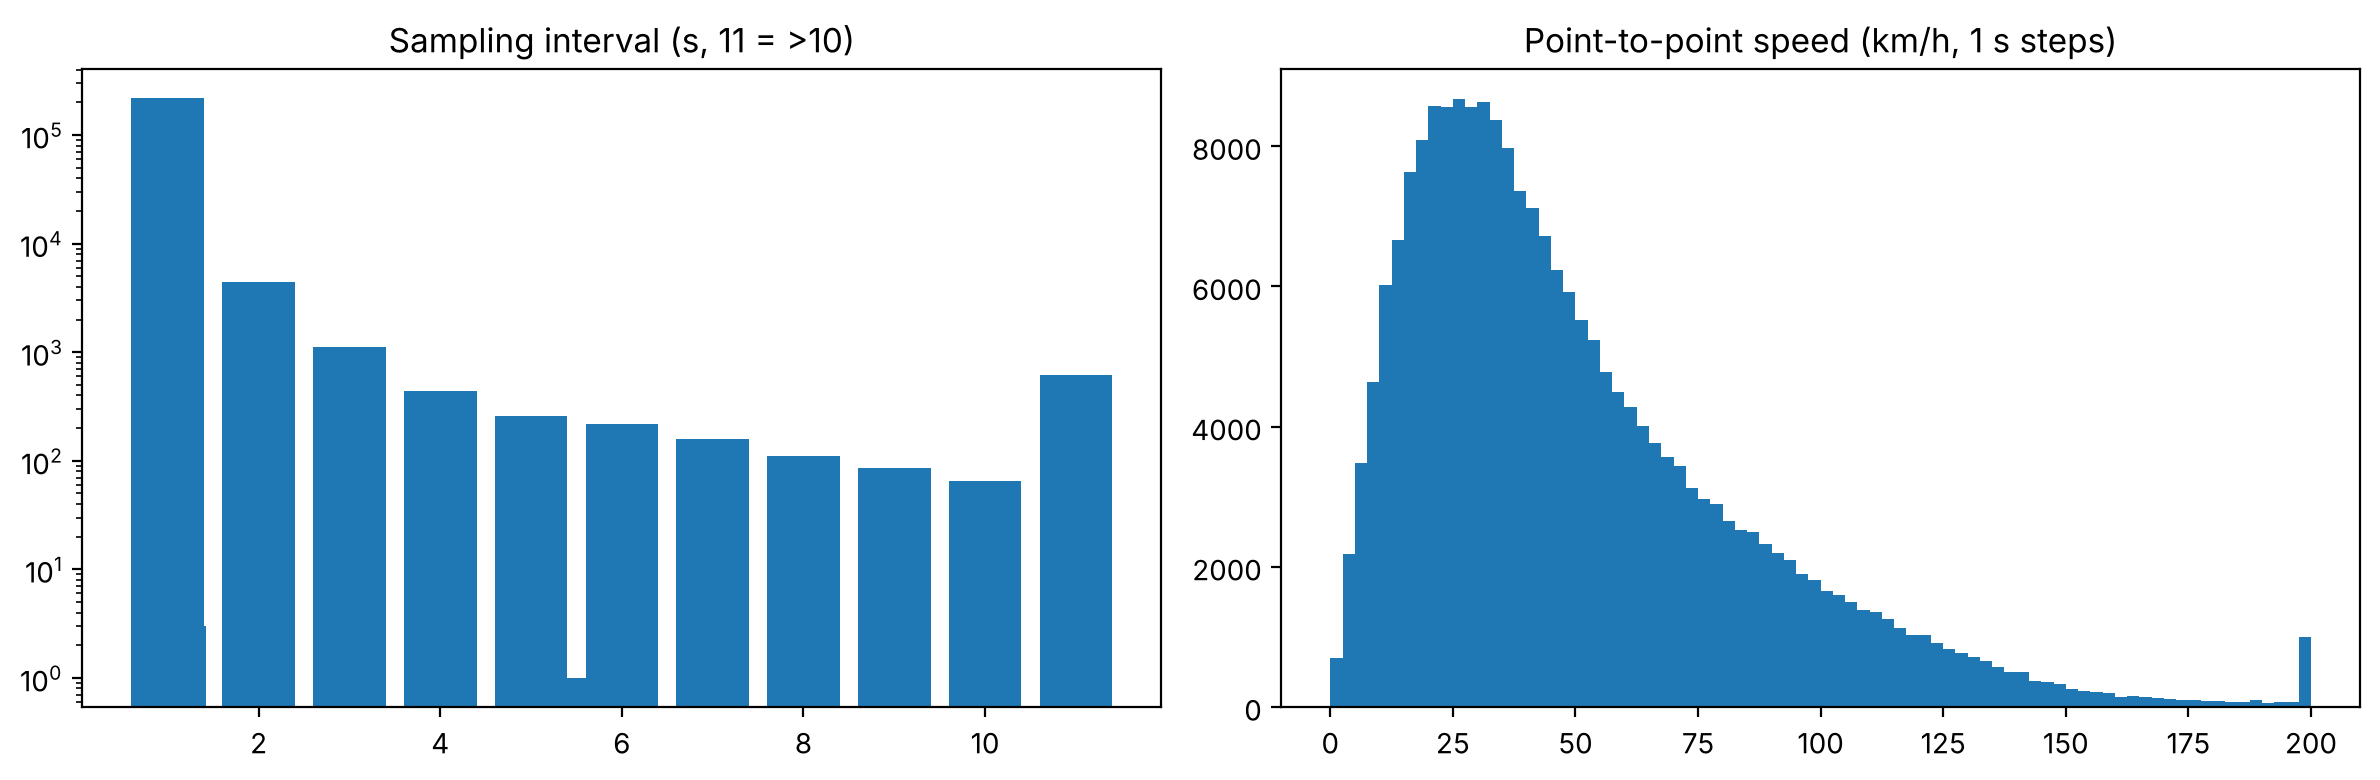

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
vals, cnt = np.unique(np.minimum(dts, 11), return_counts=True)
ax[0].bar(vals, cnt); ax[0].set_yscale("log"); ax[0].set_title("Sampling interval (s, 11 = >10)")
ax[1].hist(np.minimum(spd * 3.6, 200), bins=80); ax[1].set_title("Point-to-point speed (km/h, 1 s steps)")
plt.tight_layout(); plt.savefig(f"{FIG}/eda_sampling_speed.png", dpi=120)
print(f"dt==1s: {np.mean(dts == 1):.3f}, dt>10s: {(dts > 10).sum()}, speed>200km/h steps: {(spd * 3.6 > 200).sum()}")

In [6]:
net.describe().round(3)

,nodes,arcs,weak_cc,strong_cc,largest_scc_frac,isolated,dead_ends,mean_arc_m
count,90.000,90.000,90.000,90.000,90.000,90.0,90.000,90.000
mean,22490.822,45132.722,37.200,233.467,0.949,0.0,10.611,49.473
std,30868.526,61920.285,58.149,329.422,0.056,0.0,16.386,27.143
min,299.000,649.000,1.000,2.000,0.636,0.0,0.000,15.025
25%,3655.250,7282.750,8.250,16.000,0.940,0.0,0.000,33.701
50%,9305.000,18761.500,19.000,107.000,0.964,0.0,5.500,40.519
75%,26296.500,52913.250,40.750,317.250,0.980,0.0,12.000,59.731
max,155003.000,307392.000,421.000,1942.000,1.000,0.0,81.000,168.729


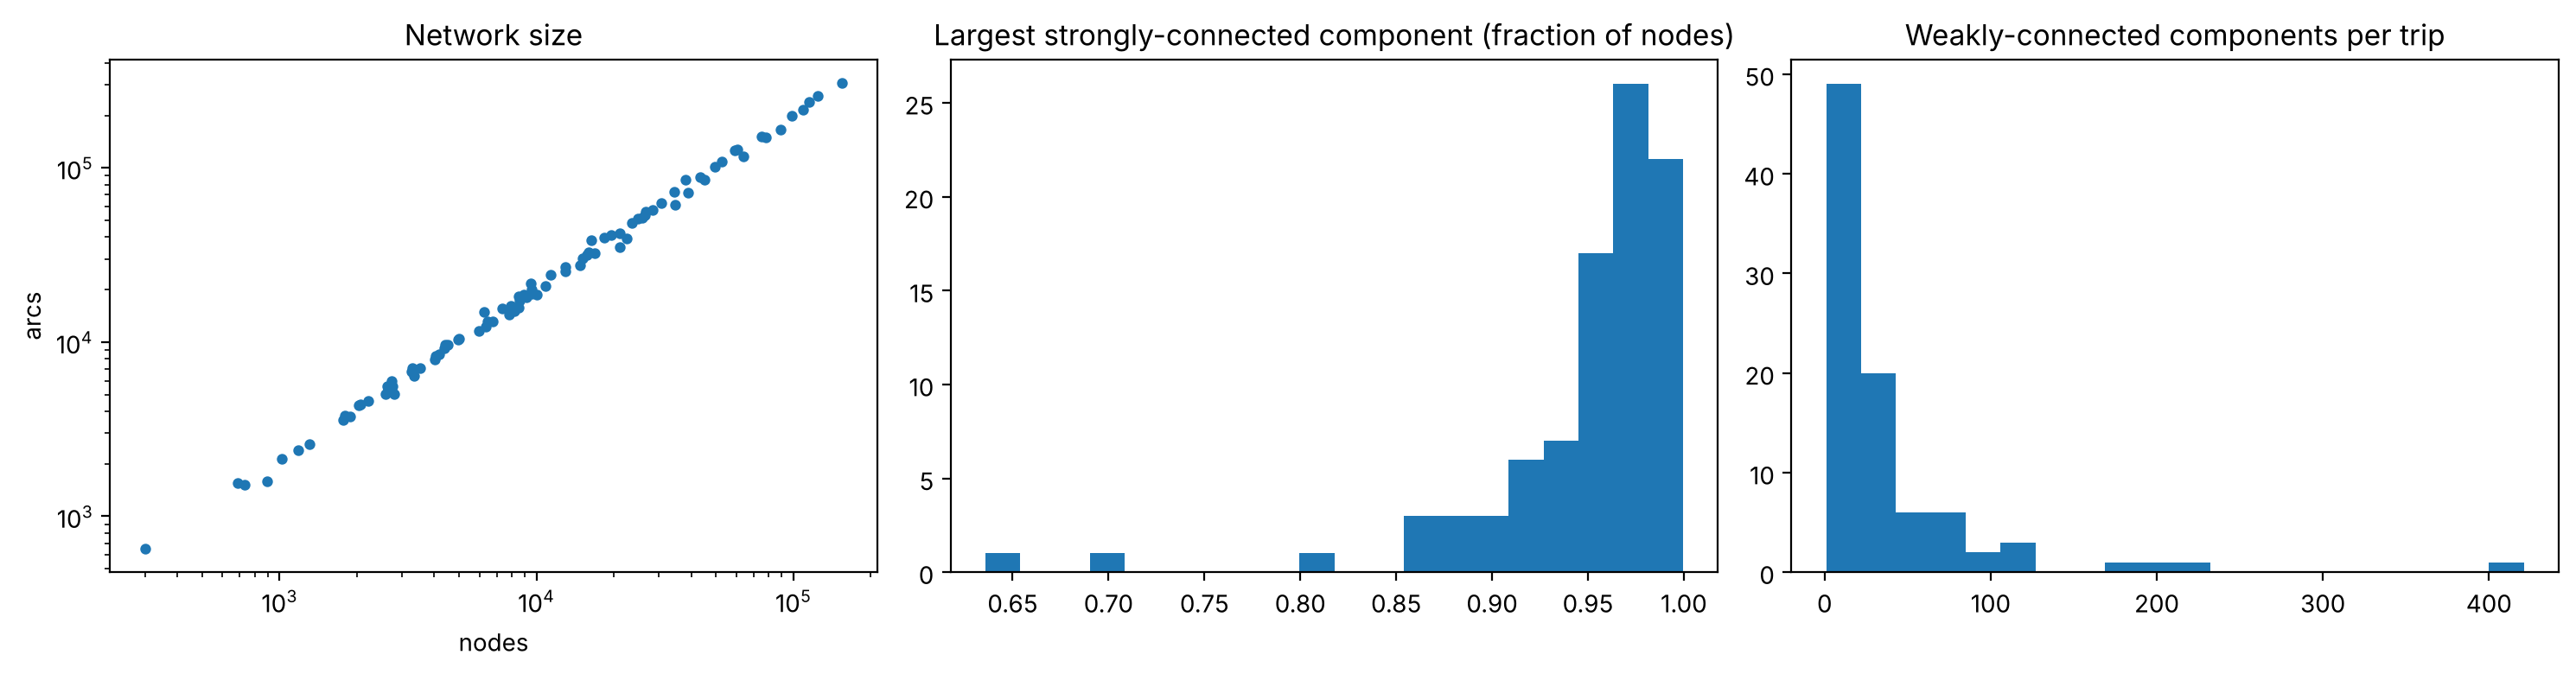

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(net.nodes, net.arcs, s=12); ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("nodes"); ax[0].set_ylabel("arcs"); ax[0].set_title("Network size")
ax[1].hist(net.largest_scc_frac, bins=20); ax[1].set_title("Largest strongly-connected component (fraction of nodes)")
ax[2].hist(net.weak_cc, bins=20); ax[2].set_title("Weakly-connected components per trip")
plt.tight_layout(); plt.savefig(f"{FIG}/eda_network.png", dpi=120)

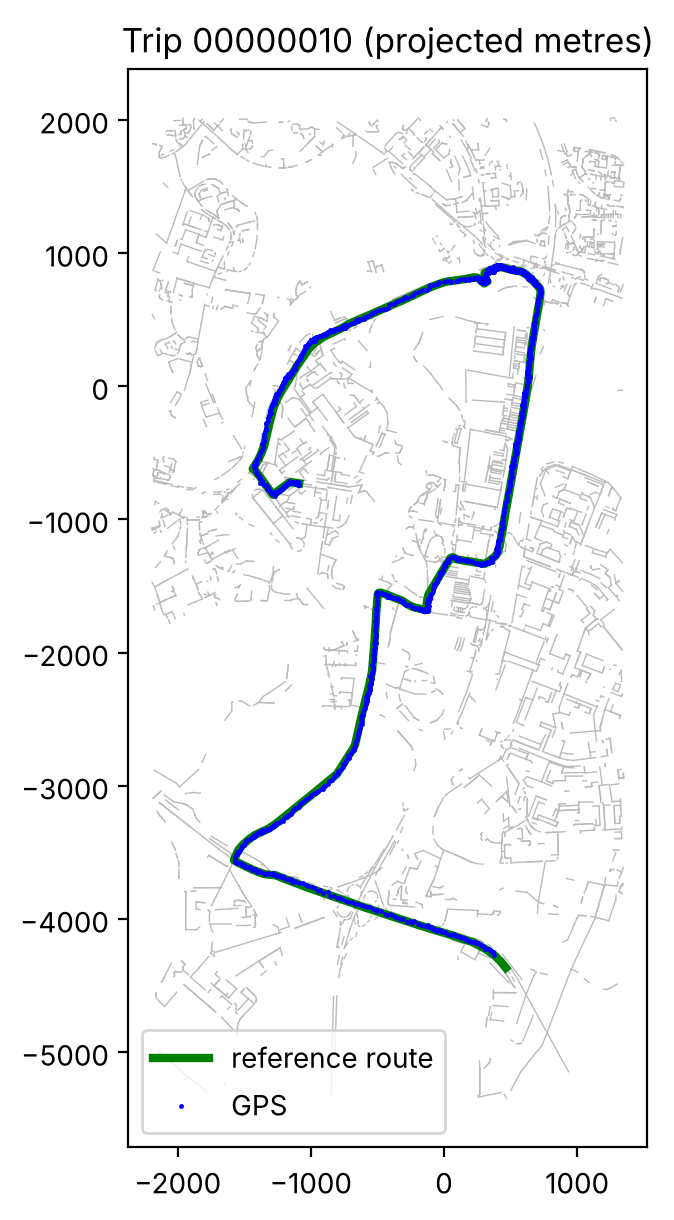

In [8]:
tr = io.load_trip("train", "00000010")
fig, ax = plt.subplots(figsize=(7, 7))
for i in np.random.default_rng(0).choice(len(tr["arcs"]), 6000, replace=False):
    ax.plot(*np.c_[tr["A"][i], tr["B"][i]], color="#bbb", lw=.5)
r = tr["route"]
ax.plot(*np.r_[tr["A"][r], tr["B"][r][-1:]].T, color="g", lw=3, label="reference route")
ax.plot(*tr["pxy"].T, ".", ms=1.5, color="b", label="GPS")
ax.set_aspect("equal"); ax.legend(); ax.set_title("Trip 00000010 (projected metres)")
plt.savefig(f"{FIG}/eda_trip_00000010.png", dpi=120)